In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
class Mnist:
    """Three-layer network (784 -> 50 -> 100 -> 10) for MNIST digits.

    Uses pretrained weights from sample_weight.pkl and runs forward
    propagation with sigmoid hidden layers and a softmax output.
    """

    def __init__(self, weight_file='sample_weight.pkl'):
        self.weight_file = weight_file
        self.params = {}
        self.init_network()

    def init_network(self):
        with open(self.weight_file, 'rb') as f:
            self.params = pickle.load(f)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def softmax(self, x):
        x = x - np.max(x, axis=-1, keepdims=True)
        return np.exp(x) / np.sum(np.exp(x), axis=-1, keepdims=True)

    def load_image(self, path):
        img = Image.open(path).convert('L').resize((28, 28))
        return np.array(img, dtype=np.float32)

    def center_image(self, img):
        # same normalization as MNIST: fit the digit in a 20x20 box,
        # then center it in 28x28 by its center of mass
        ys, xs = np.nonzero(img > 0)
        crop = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
        h, w = crop.shape
        scale = 20 / max(h, w)
        new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
        crop = Image.fromarray(crop.astype(np.uint8)).resize((new_w, new_h), Image.LANCZOS)
        crop = np.array(crop, dtype=np.float32)

        out = np.zeros((28, 28), dtype=np.float32)
        y0, x0 = (28 - new_h) // 2, (28 - new_w) // 2
        out[y0:y0 + new_h, x0:x0 + new_w] = crop

        rows, cols = np.indices(out.shape)
        cy = (rows * out).sum() / out.sum()
        cx = (cols * out).sum() / out.sum()
        return np.roll(out, (int(round(14 - cy)), int(round(14 - cx))), axis=(0, 1))

    def preprocess(self, img):
        return self.center_image(img).reshape(1, 784) / 255.0

    def forward(self, x):
        w1, w2, w3 = self.params['W1'], self.params['W2'], self.params['W3']
        b1, b2, b3 = self.params['b1'], self.params['b2'], self.params['b3']

        a1 = np.dot(x, w1) + b1
        z1 = self.sigmoid(a1)
        a2 = np.dot(z1, w2) + b2
        z2 = self.sigmoid(a2)
        a3 = np.dot(z2, w3) + b3
        return self.softmax(a3)

    def predict(self, img):
        y = self.forward(self.preprocess(img))
        return int(np.argmax(y))

In [3]:
mnist = Mnist('sample_weight.pkl')
for key in ['W1', 'b1', 'W2', 'b2', 'W3', 'b3']:
    print(key, mnist.params[key].shape)

W1 (784, 50)
b1 (50,)
W2 (50, 100)
b2 (100,)
W3 (100, 10)
b3 (10,)


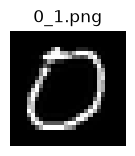

Success: Image 0_1.png is for digit 0 is recognized as 0.


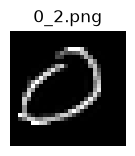

Success: Image 0_2.png is for digit 0 is recognized as 0.


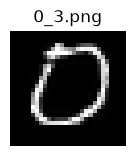

Success: Image 0_3.png is for digit 0 is recognized as 0.


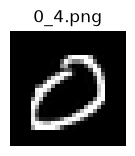

Success: Image 0_4.png is for digit 0 is recognized as 0.


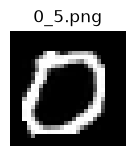

Success: Image 0_5.png is for digit 0 is recognized as 0.


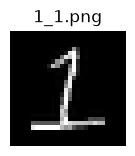

Success: Image 1_1.png is for digit 1 is recognized as 1.


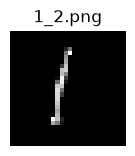

Success: Image 1_2.png is for digit 1 is recognized as 1.


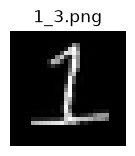

Success: Image 1_3.png is for digit 1 is recognized as 1.


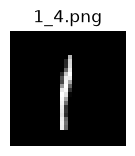

Success: Image 1_4.png is for digit 1 is recognized as 1.


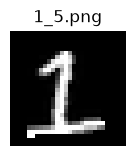

Fail: Image 1_5.png is for digit 1 but the inference result is 2.


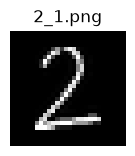

Success: Image 2_1.png is for digit 2 is recognized as 2.


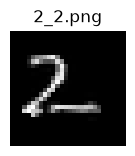

Success: Image 2_2.png is for digit 2 is recognized as 2.


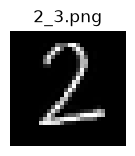

Success: Image 2_3.png is for digit 2 is recognized as 2.


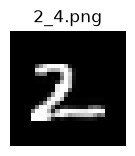

Success: Image 2_4.png is for digit 2 is recognized as 2.


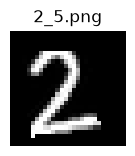

Success: Image 2_5.png is for digit 2 is recognized as 2.


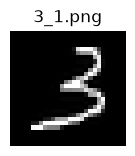

Success: Image 3_1.png is for digit 3 is recognized as 3.


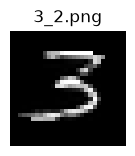

Success: Image 3_2.png is for digit 3 is recognized as 3.


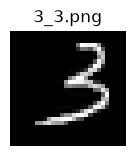

Success: Image 3_3.png is for digit 3 is recognized as 3.


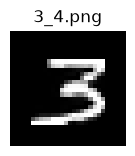

Success: Image 3_4.png is for digit 3 is recognized as 3.


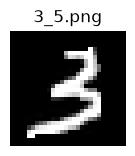

Success: Image 3_5.png is for digit 3 is recognized as 3.


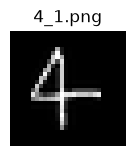

Success: Image 4_1.png is for digit 4 is recognized as 4.


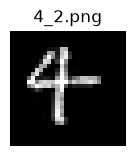

Fail: Image 4_2.png is for digit 4 but the inference result is 9.


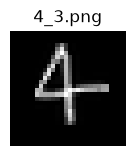

Success: Image 4_3.png is for digit 4 is recognized as 4.


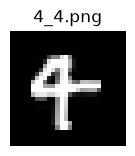

Fail: Image 4_4.png is for digit 4 but the inference result is 9.


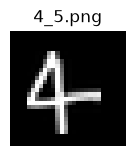

Success: Image 4_5.png is for digit 4 is recognized as 4.


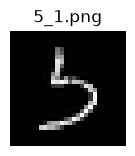

Success: Image 5_1.png is for digit 5 is recognized as 5.


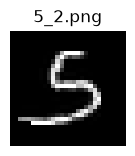

Fail: Image 5_2.png is for digit 5 but the inference result is 3.


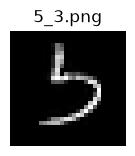

Success: Image 5_3.png is for digit 5 is recognized as 5.


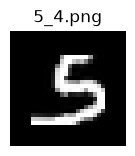

Fail: Image 5_4.png is for digit 5 but the inference result is 3.


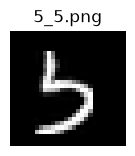

Success: Image 5_5.png is for digit 5 is recognized as 5.


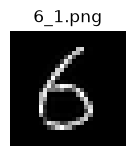

Fail: Image 6_1.png is for digit 6 but the inference result is 5.


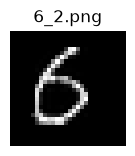

Fail: Image 6_2.png is for digit 6 but the inference result is 5.


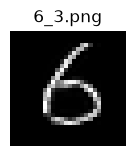

Fail: Image 6_3.png is for digit 6 but the inference result is 5.


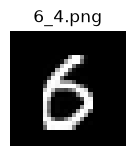

Fail: Image 6_4.png is for digit 6 but the inference result is 0.


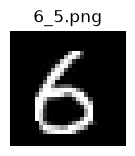

Success: Image 6_5.png is for digit 6 is recognized as 6.


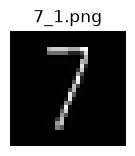

Success: Image 7_1.png is for digit 7 is recognized as 7.


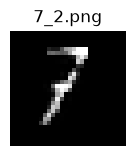

Success: Image 7_2.png is for digit 7 is recognized as 7.


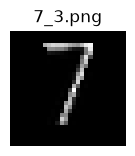

Success: Image 7_3.png is for digit 7 is recognized as 7.


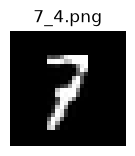

Success: Image 7_4.png is for digit 7 is recognized as 7.


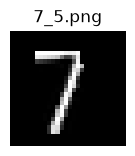

Success: Image 7_5.png is for digit 7 is recognized as 7.


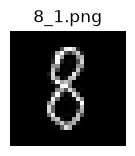

Success: Image 8_1.png is for digit 8 is recognized as 8.


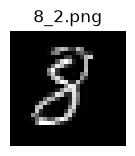

Success: Image 8_2.png is for digit 8 is recognized as 8.


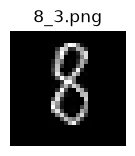

Success: Image 8_3.png is for digit 8 is recognized as 8.


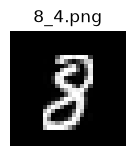

Success: Image 8_4.png is for digit 8 is recognized as 8.


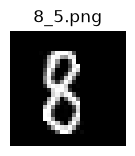

Success: Image 8_5.png is for digit 8 is recognized as 8.


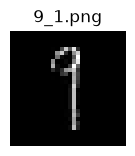

Fail: Image 9_1.png is for digit 9 but the inference result is 7.


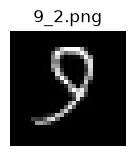

Success: Image 9_2.png is for digit 9 is recognized as 9.


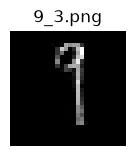

Fail: Image 9_3.png is for digit 9 but the inference result is 7.


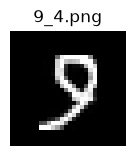

Success: Image 9_4.png is for digit 9 is recognized as 9.


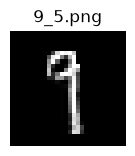

Fail: Image 9_5.png is for digit 9 but the inference result is 7.


In [4]:
image_dir = 'digitimages'
n_correct = 0
n_total = 0

for digit in range(10):
    for ver in range(1, 6):
        file_name = f'{digit}_{ver}.png'
        img = mnist.load_image(os.path.join(image_dir, file_name))
        result = mnist.predict(img)

        plt.figure(figsize=(1.5, 1.5))
        plt.imshow(img, cmap='gray')
        plt.title(file_name)
        plt.axis('off')
        plt.show()

        if result == digit:
            n_correct += 1
            print(f'Success: Image {file_name} is for digit {digit} is recognized as {result}.')
        else:
            print(f'Fail: Image {file_name} is for digit {digit} but the inference result is {result}.')
        n_total += 1

In [5]:
print(f'Accuracy: {n_correct}/{n_total} = {n_correct / n_total:.2%}')

Accuracy: 38/50 = 76.00%
